# Lululime — Should leadership scrap repairs and expand loyalty?
Dataverse 2026 · Final notebook. Edit `summary.py`, then generate the notebook with:
`jupytext --to notebook summary.py -o summary.ipynb`, and run it top to bottom.

## 1. Problem framing
A competitor opened across the street in **March 2024** and targeted younger customers with lower prices.
Lululime responded with a loyalty program (Jun 2024), a Pilates campaign (Jan–Mar 2025) and free repairs (Apr 2025).
Revenue has since recovered. Leadership credits loyalty and plans to **expand loyalty perks and shut down free repairs**,
believing repairs only cost money and cannibalize outerwear sales.

We test that plan through two numbers:
- **ARR:** revenue from repeat customers (any visit after their signup date) over the trailing 12 months.
- **Profit:** revenue − production costs − repair costs − redeemed points ($1 per 20 points).

In [1]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import pandas as pd

from src import config as C
from src.metrics import load

# Shared chart style (validated palette: blue / orange; recessive grid)
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#5f5e5a", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 11,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "lines.linewidth": 2,
})
EVENT_LABELS = {
    "competitor_open": "Competitor opens", "loyalty_launch": "Loyalty launch",
    "pilates_start": "Pilates push", "repairs_launch": "Free repairs",
    "website_launch": "Website", "new_manager": "New manager",
}


def mark_events(ax, ymax):
    """Dashed vertical line and label for each initiative."""
    for i, (key, label) in enumerate(EVENT_LABELS.items()):
        d = C.EVENTS[key]
        ax.axvline(d, color=INK2, lw=0.8, ls=(0, (3, 3)), zorder=1)
        ax.text(d, ymax * (0.995 - 0.035 * (i % 2)), " " + label, color=INK2, fontsize=9, va="top")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 5, 9]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

## 2. Data & methodology
All cleaning and joining lives in `src/` (rules in `docs/data_notes.md`, decisions in `docs/decisions_log.md`):
1. **Clean:** drop 1,016 exact duplicate sales rows; blank tier before the loyalty launch = "Pre-loyalty"; blank points = 0.
2. **Join:** sales → items on `item_id`, → customers on `customer_id` (left joins, one-to-one lookup check).
3. **Baskets:** lines grouped by `transaction_id` into visits; `points_redeemed` summed per transaction.
4. **Metrics:** profit per line; repair cost at drop-off only (unpicked drop-offs still count); returns and repair
   pickups linked to their original on `original_transaction_id` + `item_id`.

The build below reruns every step from the raw CSVs and prints the integrity checks.

In [2]:
from src.tables import build_all
_ = build_all(write=False)


== Row counts ==
  raw sales rows           352,014
  duplicates dropped         1,016
  clean sales rows         350,998
  lines (after joins)      350,998
  visits                   190,156
  customers                 14,440  (14,440 with sales)
  customer_month           465,331
  links                     22,749

== Join integrity ==
  [PASS] row count unchanged by joins
  [PASS] revenue unchanged by joins: before $26,204,614.30 / after $26,204,614.30
  [PASS] every line matched an item and a customer
  [PASS] revenue ties out across lines / visits / customer_month

== Costs ==
  [PASS] no cost on Pickup rows (5,221 rows, cost $0.00)
  [PASS] repairs carry repair cost only, no production cost
  repair cost total (drop-offs)  $187,983.00
  RETURN_COST_REVERSES = True

== Links ==
  [PASS] Return -> Purchase: 17,387/17,387 linked rows resolve
  [INFO] Return -> Purchase: 141 rows have no original_transaction_id (dates 2022-11-01..2022-11-24; purchase predates data start)
  [PASS] Re

In [3]:
lines = load()                      # one row per sales line (the shared, cleaned, joined table)
visits = load("visits")             # one row per transaction (basket)
customers = load("customers")       # one row per customer: churn, ARR, repair use, membership
customer_month = load("customer_month")
print(f"{len(lines):,} lines · {len(visits):,} visits · {len(customers):,} customers")

350,998 lines · 190,156 visits · 14,440 customers


## 3. ARR over time (Stream D, slide 3)
ARR fell for a year after the competitor opened, then recovered to a new high. Plotted from Nov 2023, the first
month with a full 12 months of history. ARR is a rolling total, so it lags real changes by up to a year.

In [4]:
arr = customer_month.groupby("month")["arr_12m"].sum()
arr = arr[arr.index >= "2023-11-01"]
trough_m = arr.idxmin()

pd.Series({
    "ARR at competitor open, Mar 2024 ($M)": arr[C.COMPETITOR_OPEN.to_period("M").to_timestamp()] / 1e6,
    f"ARR low, {trough_m:%b %Y} ($M)": arr.min() / 1e6,
    "ARR Oct 2026 ($M)": arr.iloc[-1] / 1e6,
    "Change from low to Oct 2026 (%)": (arr.iloc[-1] / arr.min() - 1) * 100,
}).round(2)

ARR at competitor open, Mar 2024 ($M)     6.23
ARR low, Feb 2025 ($M)                    5.53
ARR Oct 2026 ($M)                         6.67
Change from low to Oct 2026 (%)          20.75
dtype: float64

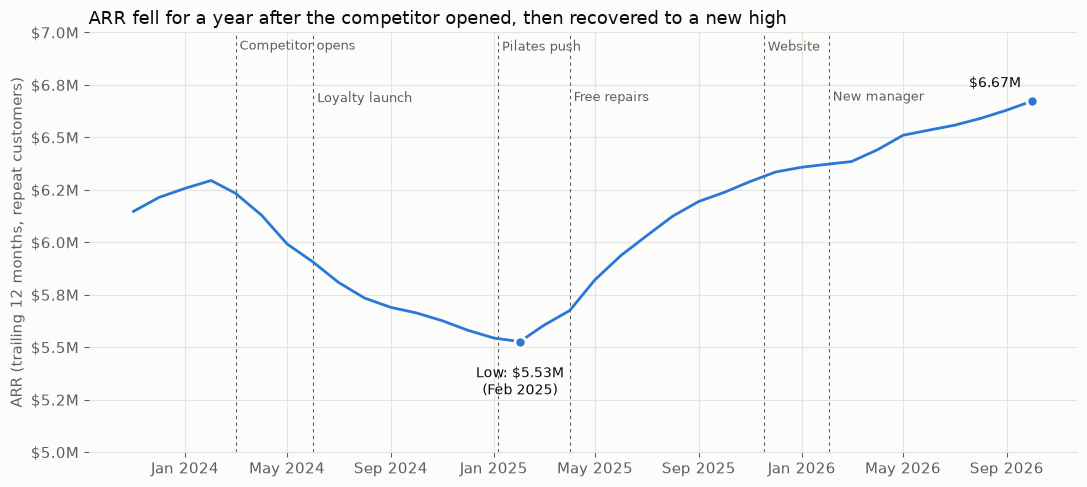

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(arr.index, arr / 1e6, color=BLUE)
ax.plot([trough_m, arr.index[-1]], [arr.min() / 1e6, arr.iloc[-1] / 1e6], "o", color=BLUE, ms=8,
        mec="#fcfcfb", mew=2, zorder=3)
ax.annotate(f"Low: ${arr.min()/1e6:.2f}M\n({trough_m:%b %Y})", (trough_m, arr.min() / 1e6),
            xytext=(0, -38), textcoords="offset points", ha="center", color=INK, fontsize=10)
ax.annotate(f"${arr.iloc[-1]/1e6:.2f}M", (arr.index[-1], arr.iloc[-1] / 1e6),
            xytext=(-8, 10), textcoords="offset points", ha="right", color=INK, fontsize=10)
ax.set_ylim(5.0, 7.0)
mark_events(ax, 7.0)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x:.1f}M"))
ax.set_title("ARR fell for a year after the competitor opened, then recovered to a new high",
             loc="left", color=INK, fontsize=13)
ax.set_ylabel("ARR (trailing 12 months, repeat customers)")
fig.tight_layout()
plt.show()

**What drove the recovery?** Each month's repeat revenue and active repeat customers, compared with the **same
calendar month in Mar 2023 – Feb 2024** (the year before the competitor), which removes seasonality.
Revenue is back above pre-competitor levels, but customers are not: the recovery is fewer customers spending more.

In [6]:
rv = visits[visits["is_repeat_visit"]]
g = rv.groupby("month").agg(revenue=("revenue", "sum"), customers=("customer_id", "nunique"))
base = g.loc["2023-03-01":"2024-02-01"].copy()
base.index = base.index.month

rows = {}
for name, (a, b) in {"Year 1 (Mar 2024 – Feb 2025)": ("2024-03-01", "2025-02-01"),
                     "Year 2 (Mar 2025 – Feb 2026)": ("2025-03-01", "2026-02-01"),
                     "Year 3 so far (Mar – Oct 2026)": ("2026-03-01", "2026-10-01")}.items():
    p, bm = g.loc[a:b], base.loc[g.loc[a:b].index.month]
    rows[name] = {
        "repeat revenue vs pre-competitor (%)": (p.revenue.sum() / bm.revenue.sum() - 1) * 100,
        "active repeat customers vs pre-competitor (%)": (p.customers.mean() / bm.customers.mean() - 1) * 100,
        "revenue per active customer vs pre-competitor (%)":
            ((p.revenue.sum() / p.customers.sum()) / (bm.revenue.sum() / bm.customers.sum()) - 1) * 100,
    }
pd.DataFrame(rows).T.round(1)

,repeat revenue vs pre-competitor (%),active repeat customers vs pre-competitor (%),revenue per active customer vs pre-competitor (%)
Year 1 (Mar 2024 – Feb 2025),-12.2,-18.7,8.0
Year 2 (Mar 2025 – Feb 2026),1.2,-8.8,11.0
Year 3 so far (Mar – Oct 2026),10.4,-5.3,16.6


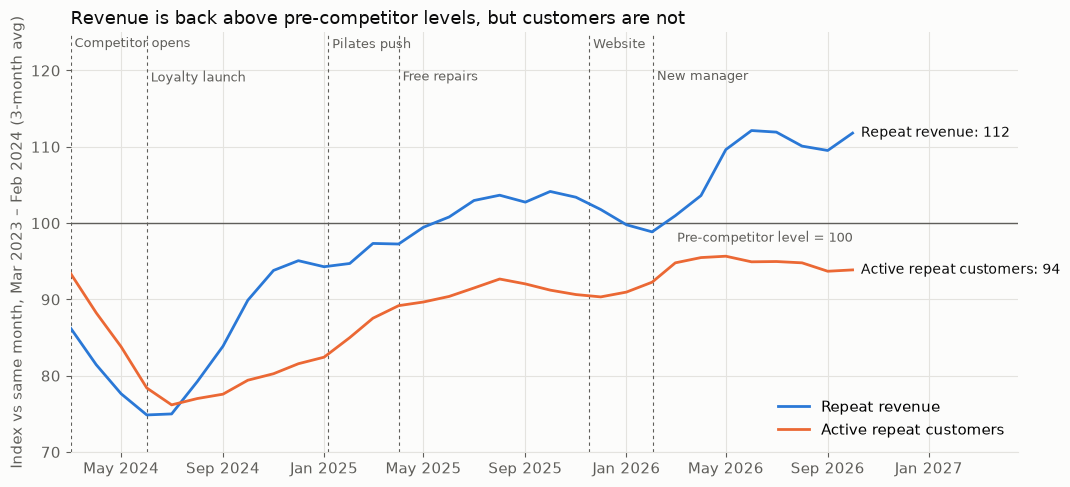

In [7]:
post = g.loc["2024-03-01":]
idx = (post.div(base.loc[post.index.month].values) * 100).rolling(3, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.axhline(100, color=INK2, lw=1)
for col, colr, lab in [("revenue", BLUE, "Repeat revenue"), ("customers", ORANGE, "Active repeat customers")]:
    ax.plot(idx.index, idx[col], color=colr, label=lab)
    ax.annotate(f"{lab}: {idx[col].iloc[-1]:.0f}", (idx.index[-1], idx[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK, fontsize=10)
ax.text(pd.Timestamp("2026-10-01"), 99, "Pre-competitor level = 100", color=INK2, fontsize=9, va="top", ha="right")
ax.set_ylim(70, 125)
mark_events(ax, 125)
ax.legend(loc="lower right", frameon=False)
ax.set_xlim(idx.index[0], idx.index[-1] + pd.Timedelta(days=200))
ax.set_title("Revenue is back above pre-competitor levels, but customers are not", loc="left", color=INK, fontsize=13)
ax.set_ylabel("Index vs same month, Mar 2023 – Feb 2024 (3-month avg)")
fig.tight_layout()
plt.show()

## 4. Competitor impact & seasonality (Stream A, slide 4)
The competitor opened on **15 March 2024**, and the data shows the hit the same day: 18–24 revenue was normal on
1–14 March (+2% vs the same days of 2023), then fell 50% on 15–31 March. Every comparison below uses the **same
months year over year** (e.g. Mar–Oct 2024 vs Mar–Oct 2023), so seasonal swings cancel out. Mar–Oct is used because
the data ends in October 2026, so it's the longest window available in every year. Full analysis, with
explanations of every step: the three notebooks in `analysis/a_competitor/`.

- **The competitor took young customers, and they never came back.** 18–24 revenue fell ~45% and is still ~45% below
  2023; every other age band recovered and grew. The store-wide recovery comes from customers aged 25 and over.
- **It broke the pipeline of young customers.** New 18–24 customers halved, and existing ones went from being as loyal
  as everyone else to the least likely to return.
- **Seasonality is large and must be controlled for:** December is ~1.9× an average month; outerwear makes ~half its
  sales in Nov–Jan. Repairs launched in April, at the start of outerwear's slowest season.

In [8]:
a_p = lines[lines["row_type"] == C.PURCHASE].copy()
a_p["year"], a_p["mon"] = a_p["date"].dt.year, a_p["date"].dt.month
A_AGES = ["18-24", "25-34", "35-44", "45-54", "55+"]


def a_mar_oct(df, year):
    """Mar–Oct of a year: the longest window that exists in all of 2023–2026 (data ends Oct 2026)."""
    return df[(df["year"] == year) & df["mon"].between(3, 10)]


a_rev = pd.DataFrame({y: a_mar_oct(a_p, y).groupby("age_band")["revenue"].sum() for y in [2023, 2024, 2025, 2026]})
a_cat = pd.DataFrame({y: a_mar_oct(a_p, y).groupby("category")["revenue"].sum() for y in [2023, 2024, 2025]})
a_lost = (a_rev[2024] - a_rev[2023]).loc[A_AGES]

a_new = customers[customers["signup_date"] >= C.DATA_START]
a_new = a_new[a_new["signup_date"].dt.month.between(3, 10)]
a_new = a_new.groupby([a_new["signup_date"].dt.year, "age_band"]).size().unstack()

pd.Series({
    "18-24 revenue, Mar–Oct 2024 vs 2023 (%)": (a_rev.loc["18-24", 2024] / a_rev.loc["18-24", 2023] - 1) * 100,
    "18-24 revenue, Mar–Oct 2026 vs 2023 (%)": (a_rev.loc["18-24", 2026] / a_rev.loc["18-24", 2023] - 1) * 100,
    "25+ revenue, Mar–Oct 2026 vs 2023 (%)": (a_rev.loc[A_AGES[1:], 2026].sum() / a_rev.loc[A_AGES[1:], 2023].sum() - 1) * 100,
    "18-24 share of revenue lost in 2024 (%)": a_lost["18-24"] / a_lost.sum() * 100,
    "18-24 share of 2023 revenue (%)": a_rev.loc["18-24", 2023] / a_rev[2023].sum() * 100,
    "New 18-24 customers, Mar–Oct 2024 vs 2023 (%)": (a_new.loc[2024, "18-24"] / a_new.loc[2023, "18-24"] - 1) * 100,
    "Leggings revenue, Mar–Oct 2024 vs 2023 (%)": (a_cat.loc["Leggings", 2024] / a_cat.loc["Leggings", 2023] - 1) * 100,
    "Outerwear revenue, Mar–Oct 2025 vs 2023 (%)": (a_cat.loc["Outerwear", 2025] / a_cat.loc["Outerwear", 2023] - 1) * 100,
}).round(1)

18-24 revenue, Mar–Oct 2024 vs 2023 (%)         -45.2
18-24 revenue, Mar–Oct 2026 vs 2023 (%)         -47.0
25+ revenue, Mar–Oct 2026 vs 2023 (%)            22.5
18-24 share of revenue lost in 2024 (%)          53.2
18-24 share of 2023 revenue (%)                  19.3
New 18-24 customers, Mar–Oct 2024 vs 2023 (%)   -46.4
Leggings revenue, Mar–Oct 2024 vs 2023 (%)      -30.2
Outerwear revenue, Mar–Oct 2025 vs 2023 (%)      -9.6
dtype: float64

**Who was hit, and when.** Each month vs the same month a year earlier. 18–24 revenue was growing until February 2024,
then ran 40–55% below the prior year from March, which is how we date the competitor's opening. From March 2025
each month is compared with a weak post-competitor month, so the jumps there are partly a bounce from a low base.

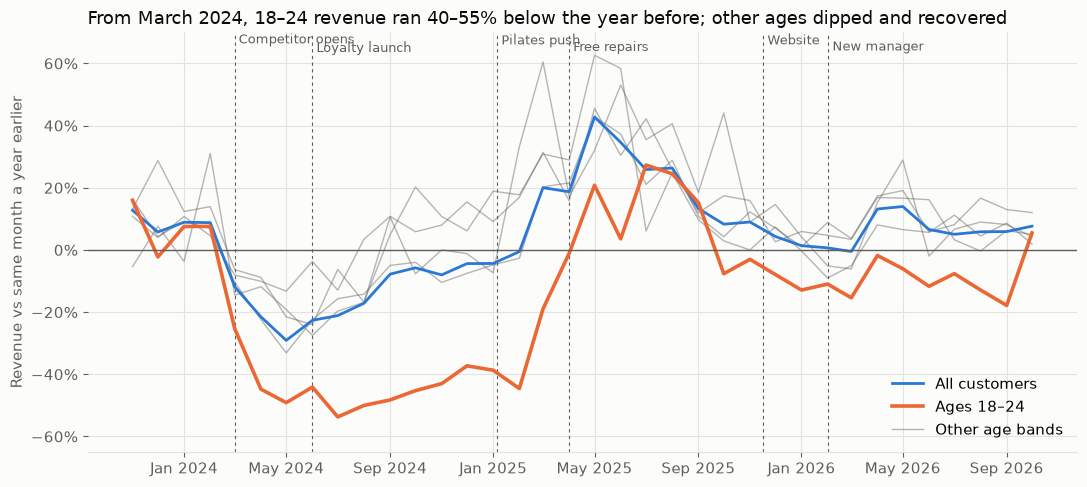

In [9]:
a_monthly = a_p.pivot_table(index="month", columns="age_band", values="revenue", aggfunc="sum")
a_monthly["All customers"] = a_monthly[A_AGES + ["Unknown"]].sum(axis=1)
a_yoy = a_monthly.pct_change(12, fill_method=None).loc["2023-11-01":] * 100

fig, ax = plt.subplots(figsize=(11, 5))
for a in A_AGES[1:]:
    ax.plot(a_yoy.index, a_yoy[a], color=INK2, lw=1, alpha=0.45)
ax.plot(a_yoy.index, a_yoy["All customers"], color=BLUE, label="All customers")
ax.plot(a_yoy.index, a_yoy["18-24"], color=ORANGE, lw=2.6, label="Ages 18–24")
ax.plot([], [], color=INK2, lw=1, alpha=0.45, label="Other age bands")
ax.axhline(0, color=INK2, lw=1)
ax.set_ylim(-65, 70)
mark_events(ax, 70)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(loc="lower right", frameon=False)
ax.set_title("From March 2024, 18–24 revenue ran 40–55% below the year before; other ages dipped and recovered",
             loc="left", color=INK, fontsize=13)
ax.set_ylabel("Revenue vs same month a year earlier")
fig.tight_layout()
plt.show()

**The competitor broke the pipeline of young customers.** Before it opened, 18–24s were as likely as anyone to come
back the following winter. Across the opening their return rate fell twice as much as older customers', and it has
stayed behind. New 18–24 customers halved over the same period, so active 18–24 customers fell from 1,513 (Mar–Oct 2023)
to 725 (Mar–Oct 2026). Windows are Nov–Feb because Nov 2022 – Feb 2023 → Nov 2023 – Feb 2024 is the only
year-on-year comparison that sits entirely before the competitor.

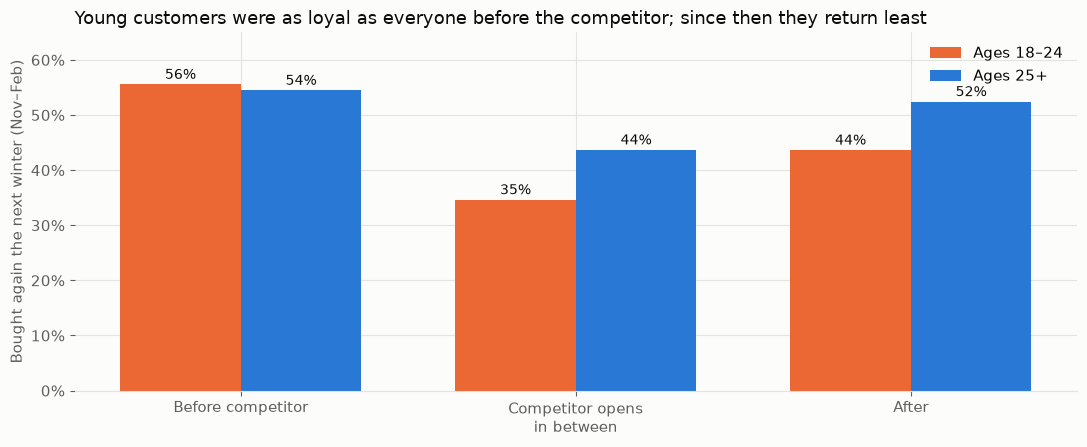

age_band,18-24,25-34,35-44,45-54,55+
Mar–Oct of,,,,,
2023,420,555,337,211,87
2024,225,593,393,178,87
2025,244,619,375,189,114
2026,201,539,336,175,102


In [10]:
a_age = customers.set_index("customer_id")["age_band"]
A_WINTERS = [("2022-11-01", "2023-03-01"), ("2023-11-01", "2024-03-01"),
             ("2024-11-01", "2025-03-01"), ("2025-11-01", "2026-03-01")]


def a_active(start, end):
    return set(a_p.loc[(a_p["date"] >= start) & (a_p["date"] < end), "customer_id"])


a_ret = {}
for (s0, e0), (s1, e1), label in zip(A_WINTERS, A_WINTERS[1:],
                                     ["Before competitor", "Competitor opens\nin between", "After"]):
    base_ids = pd.Series(sorted(a_active(s0, e0)))
    back = base_ids.isin(a_active(s1, e1))
    young = base_ids.map(a_age).eq("18-24").values
    a_ret[label] = {"Ages 18–24": back[young].mean() * 100,
                    "Ages 25+": back[base_ids.map(a_age).isin(A_AGES[1:]).values].mean() * 100}
a_ret = pd.DataFrame(a_ret).T

fig, ax = plt.subplots(figsize=(11, 4.6))
a_x = range(len(a_ret))
for i, (col, colr) in enumerate([("Ages 18–24", ORANGE), ("Ages 25+", BLUE)]):
    xs = [x + (i - 0.5) * 0.36 for x in a_x]
    ax.bar(xs, a_ret[col], 0.36, color=colr, label=col)
    for x, v in zip(xs, a_ret[col]):
        ax.text(x, v + 1, f"{v:.0f}%", ha="center", color=INK, fontsize=10)
ax.set_xticks(list(a_x), a_ret.index)
ax.set_ylim(0, 65)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(loc="upper right", frameon=False)
ax.set_title("Young customers were as loyal as everyone before the competitor; since then they return least",
             loc="left", color=INK, fontsize=13)
ax.set_ylabel("Bought again the next winter (Nov–Feb)")
fig.tight_layout()
plt.show()

a_new[A_AGES].rename_axis("Mar–Oct of").astype(int)

**Seasonality to control for.** Seasonal index = average revenue in a calendar month ÷ that row's average month × 100,
over Nov 2022 – Oct 2026 (every month appears 4 times). Four calculation methods agree within 6 points
(see `analysis/a_competitor/a2_seasonality.ipynb`).
Black Friday weekend and Boxing Week are the only discounts: 9 days and ~5% of yearly revenue. A sale day sells
~1.4× an ordinary Nov–Dec day, so most of the December peak is full-price holiday shopping.
**For any before/after comparison:** loyalty launched in June (index 76) and repairs in April (82), both quiet months,
and repairs launched as outerwear entered its slowest months.

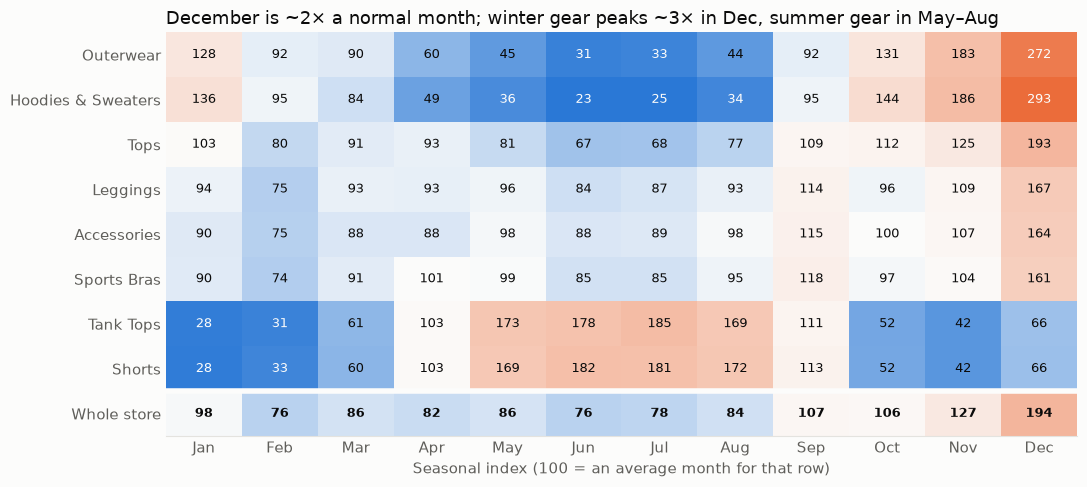

In [11]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

A_MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
a_cm = a_p.groupby(["category", "mon"])["revenue"].sum().unstack() / 4
a_heat = a_cm.div(a_cm.mean(axis=1), axis=0) * 100
a_heat = a_heat.loc[["Outerwear", "Hoodies & Sweaters", "Tops", "Leggings", "Accessories",
                     "Sports Bras", "Tank Tops", "Shorts"]]
a_store = a_p.groupby("mon")["revenue"].sum() / 4
a_heat.loc["Whole store"] = a_store / a_store.mean() * 100

fig, ax = plt.subplots(figsize=(11, 5))
a_cmap = LinearSegmentedColormap.from_list("blue_orange", [BLUE, "#fcfcfb", ORANGE])
ax.imshow(a_heat.values, cmap=a_cmap, norm=TwoSlopeNorm(vcenter=100, vmin=25, vmax=300), aspect="auto")
ax.set_xticks(range(12), A_MONTHS)
ax.set_yticks(range(len(a_heat)), a_heat.index)
ax.axhline(len(a_heat) - 1.5, color="#fcfcfb", lw=4)
ax.grid(False)
ax.tick_params(length=0)
for i in range(a_heat.shape[0]):
    for j in range(12):
        v = a_heat.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                color="#fcfcfb" if (v > 220 or v < 40) else INK,
                fontweight="bold" if a_heat.index[i] == "Whole store" else "normal")
ax.set_title("December is ~2× a normal month; winter gear peaks ~3× in Dec, summer gear in May–Aug",
             loc="left", color=INK, fontsize=13)
ax.set_xlabel("Seasonal index (100 = an average month for that row)")
fig.tight_layout()
plt.show()

## 5. Loyalty program: revenue vs profit, points-funded returns (Stream B, slides 5-6)

## 6. Repairs: churn and cost vs ARR at risk, with scenarios (Stream C, slides 7-8)
Leadership says repairs "only cost money". We test that by asking whether repair users stay longer, and whether
what they bring in outweighs what repairs cost. Full analysis: `analysis/c_repairs/` (C-1, C-2).

- **Repair users churn far less, even against similar customers:** 15% vs 66% for non-users of the same age band and
  pre-launch spend who were still buying after launch (a gap of 51 points).
- **Slow repairs go with churn:** 24% churn when a user's typical turnaround is over 20 days, vs 11–13% otherwise.
- **Repairs cost $134K a year, but repair users hold 77% of ARR.** Scrapping them pays off only if repairs cause
  **less than 9%** of the churn gap. Even at 25%, the store loses ~$366K of profit to save $134K.

**Who we compare.** Only customers who visited in the year before repairs launched (Apr 2024 – Mar 2025), so everyone
could have used repairs. Users are compared with non-users in the same age band × pre-launch spend quartile, weighted
by the number of users per cell. Raw churn (13% vs 77%) mostly compares engaged with lapsed customers: 56% of non-users
in this cohort stopped visiting *before* repairs existed. So our headline gap also requires a purchase after launch.
Counting purchase visits only (a pickup trip is a visit) changes the gap by less than 1 point.

In [12]:
c_pre = visits[visits["date"].between(C.REPAIRS_LAUNCH - pd.DateOffset(years=1),
                                      C.REPAIRS_LAUNCH - pd.Timedelta(days=1))]
c_cust = customers.set_index("customer_id")
c_coh = c_cust.loc[c_pre["customer_id"].unique()].copy()
c_coh["pre_spend"] = c_pre.groupby("customer_id")["revenue"].sum()
c_coh["spend_q"] = pd.qcut(c_coh["pre_spend"].rank(method="first"), 4, labels=["Q1", "Q2", "Q3", "Q4"])
c_last_buy = visits[visits["has_purchase"]].groupby("customer_id")["date"].max()
c_coh["churned_purchase"] = (C.AS_OF_DATE - c_coh.index.map(c_last_buy)).days > C.CHURN_DAYS
c_post = visits[(visits["date"] >= C.REPAIRS_LAUNCH) & visits["has_purchase"]]
c_coh["post_purchases"] = c_post.groupby("customer_id").size().reindex(c_coh.index).fillna(0)


def c_matched(d, col="churned"):
    """Churn of users vs non-users within age band × spend quartile, weighted by users per cell."""
    g = (d.groupby(["age_band", "spend_q", "used_repair"], observed=True)[col]
          .agg(["mean", "size"]).unstack("used_repair").dropna())
    w = g[("size", True)]
    return {"Repair users": (g[("mean", True)] * w).sum() / w.sum(),
            "Non-users": (g[("mean", False)] * w).sum() / w.sum()}


c_still = c_coh[c_coh["post_purchases"] >= 1]
c_churn = pd.DataFrame({
    "Raw": c_coh.groupby("used_repair")["churned"].mean().rename({True: "Repair users", False: "Non-users"}),
    "Matched": c_matched(c_coh),
    "Matched, purchase visits only": c_matched(c_coh, "churned_purchase"),
    "Matched, still buying after launch": c_matched(c_still),
}).T[["Repair users", "Non-users"]]
c_churn["Gap (pts)"] = c_churn["Repair users"] - c_churn["Non-users"]
C_GAP = -c_churn.loc["Matched, still buying after launch", "Gap (pts)"]   # used in the scenarios below
(c_churn * 100).round(1)

,Repair users,Non-users,Gap (pts)
Raw,14.7,84.2,-69.4
Matched,14.7,81.1,-66.4
"Matched, purchase visits only",15.2,81.2,-66.0
"Matched, still buying after launch",14.8,65.7,-50.9


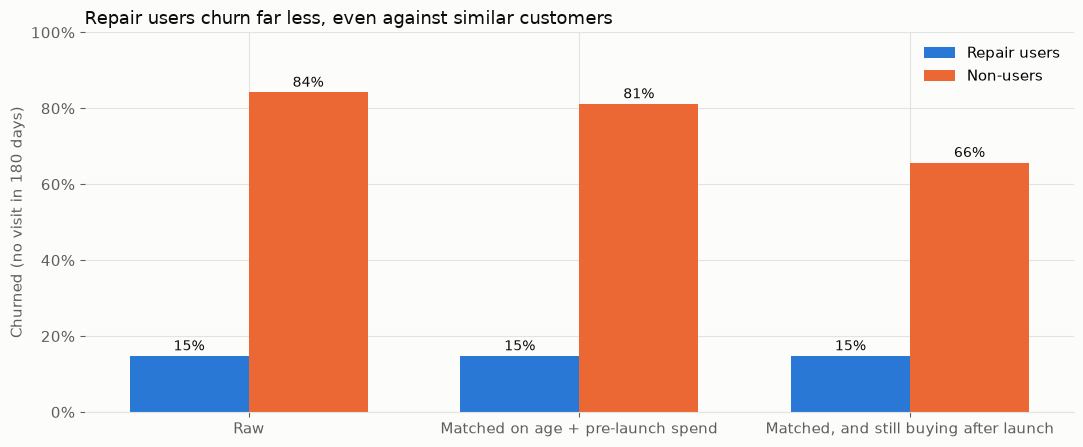

In [13]:
c_show = ["Raw", "Matched", "Matched, still buying after launch"]
c_x = range(len(c_show))
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, (col, colr) in enumerate([("Repair users", BLUE), ("Non-users", ORANGE)]):
    xs = [x + (i - 0.5) * 0.36 for x in c_x]
    ax.bar(xs, c_churn.loc[c_show, col] * 100, 0.36, color=colr, label=col)
    for x, v in zip(xs, c_churn.loc[c_show, col] * 100):
        ax.text(x, v + 1.5, f"{v:.0f}%", ha="center", color=INK, fontsize=10)
ax.set_xticks(list(c_x), ["Raw", "Matched on age + pre-launch spend", "Matched, and still buying after launch"])
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(loc="upper right", frameon=False)
ax.set_title("Repair users churn far less, even against similar customers", loc="left", color=INK, fontsize=13)
ax.set_ylabel("Churned (no visit in 180 days)")
fig.tight_layout()
plt.show()

**Turnaround.** Each repair user's median days from drop-off to pickup (median 13 days overall, range 5–47).
Not matched, and users in the slowest bucket also made fewer drop-offs, so read this as a warning sign, not proof.

In [14]:
c_rep = load("links").query("link_type == 'repair' and resolved")
c_days = c_rep.groupby("customer_id")["days_between"].median()
c_turn = (c_cust.loc[c_days.index]
          .assign(turnaround=pd.cut(c_days, [-float("inf"), 10, 20, float("inf")],
                                    labels=["≤10 days", "11–20 days", ">20 days"]))
          .groupby("turnaround", observed=True)
          .agg(churn_pct=("churned", "mean"), users=("churned", "size"), avg_dropoffs=("n_repair_dropoffs", "mean")))
c_turn["churn_pct"] *= 100
c_turn.round(1)

,churn_pct,users,avg_dropoffs
turnaround,,,
≤10 days,13.5,630,2.1
11–20 days,11.2,1209,2.9
>20 days,23.6,280,1.8


**Cost saved vs profit at risk (scenarios).** Cost saved = repair cost in the last 12 months (Nov 2025 – Oct 2026).
ARR at risk = repair users' ARR × the 51-point churn gap. Profit at risk = ARR at risk × repair users' margin before
repair cost (repair cost is already in "cost saved"). We can't prove how much of the gap repairs *cause*, so we
assume 25% / 50% / 100% and solve for the break-even share. Not included: possible outerwear cannibalization.

In [15]:
c_since = C.AS_OF_DATE - pd.DateOffset(months=C.ARR_WINDOW_MONTHS)
c_cost = lines.loc[lines["date"] > c_since, "repair_cost_amt"].sum()
c_users = c_cust[c_cust["used_repair"]]
c_uv = visits[(visits["date"] > c_since) & visits["customer_id"].isin(c_users.index)]
c_margin = (c_uv["profit"] + c_uv["repair_cost"]).sum() / c_uv["revenue"].sum()
c_users_arr = c_users["arr_12m"].sum()
C_BREAK_EVEN = c_cost / (c_users_arr * C_GAP * c_margin)

c_scen = pd.DataFrame({f"{s:.0%} caused by repairs": {
    "ARR lost ($K)": c_users_arr * C_GAP * s / 1e3,
    "Profit lost ($K)": c_users_arr * C_GAP * s * c_margin / 1e3,
    "Repair cost saved ($K)": c_cost / 1e3,
    "Net from scrapping ($K)": (c_cost - c_users_arr * C_GAP * s * c_margin) / 1e3,
} for s in [0.25, 0.5, 1.0]}).T

print(f"Repair cost, last 12 months: ${c_cost:,.0f} · repair users' ARR: ${c_users_arr/1e6:.2f}M "
      f"({c_users_arr / c_cust['arr_12m'].sum():.0%} of company ARR) · margin before repair cost: {c_margin:.0%}")
print(f"Scrapping repairs pays off only if less than {C_BREAK_EVEN:.0%} of the churn gap is caused by repairs.")
c_scen.round(0)

Repair cost, last 12 months: $133,542 · repair users' ARR: $5.12M (77% of company ARR) · margin before repair cost: 56%
Scrapping repairs pays off only if less than 9% of the churn gap is caused by repairs.


,ARR lost ($K),Profit lost ($K),Repair cost saved ($K),Net from scrapping ($K)
25% caused by repairs,652.0,366.0,134.0,-233.0
50% caused by repairs,1304.0,733.0,134.0,-599.0
100% caused by repairs,2608.0,1465.0,134.0,-1332.0


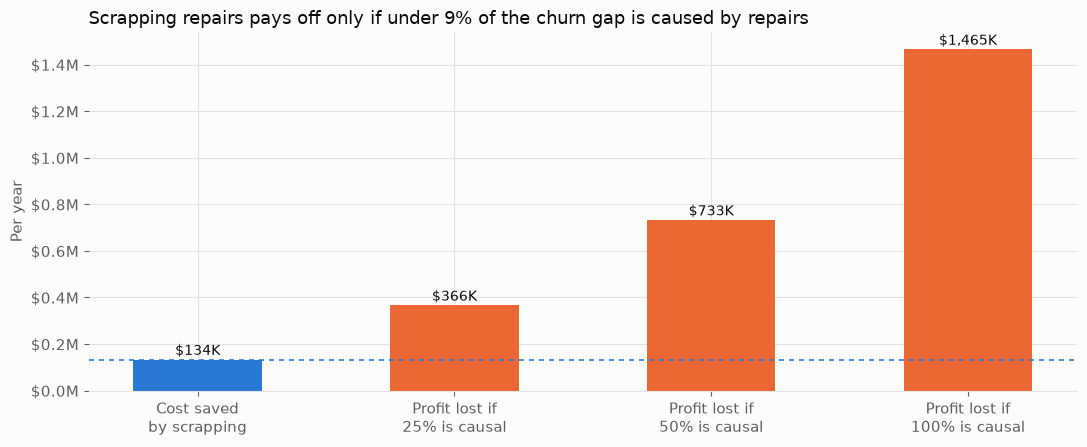

In [16]:
c_labels = ["Cost saved\nby scrapping"] + [f"Profit lost if\n{s} is causal" for s in ["25%", "50%", "100%"]]
c_vals = [c_cost / 1e3] + list(c_scen["Profit lost ($K)"])
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.bar(c_labels, c_vals, 0.5, color=[BLUE] + [ORANGE] * 3)
for x, v in enumerate(c_vals):
    ax.text(x, v + 20, f"${v:,.0f}K", ha="center", color=INK, fontsize=10)
ax.axhline(c_cost / 1e3, color=BLUE, lw=1.2, ls=(0, (3, 3)))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x/1e3:.1f}M"))
ax.set_title(f"Scrapping repairs pays off only if under {C_BREAK_EVEN:.0%} of the churn gap is caused by repairs",
             loc="left", color=INK, fontsize=13)
ax.set_ylabel("Per year")
fig.tight_layout()
plt.show()

## 7. Pilates campaign (Stream D, slide 9)
Customers who signed up during the campaign (Jan 6 – Mar 31, 2025): the 360 from the Pilates campaign vs the 417
from other channels in the **same weeks**, so season and store conditions match. The data has no campaign cost,
so this measures value delivered, not ROI.

In [17]:
cohort = customers[customers["signup_date"].between(C.PILATES_START, C.PILATES_END)].copy()
cohort["group"] = cohort["acquisition_channel"].eq("Pilates Campaign").map(
    {True: "Pilates Campaign", False: "Other channels, same weeks"})

pv = visits.merge(cohort[["customer_id", "group"]], on="customer_id")
pv["days"] = (pv["date"] - pv["signup_date"]).dt.days
for d in [90, 180, 365]:
    cohort[f"came_back_{d}d"] = cohort["customer_id"].isin(pv.loc[pv["days"].between(1, d), "customer_id"])
cohort["one_visit_only"] = cohort["n_visits"] == 1
cohort["last_visit_in_campaign"] = cohort["last_visit"] <= C.PILATES_END

first_year = (pv[pv["days"] <= 365].groupby(["customer_id", "group"])
              .agg(revenue=("revenue", "sum"), profit=("profit", "sum")).reset_index())
pilates = pd.concat([
    cohort.groupby("group")[["came_back_90d", "came_back_180d", "came_back_365d", "one_visit_only",
                             "last_visit_in_campaign", "churned"]].mean().mul(100).round(1),
    first_year.groupby("group")[["revenue", "profit"]].mean().round(0).add_prefix("first_year_").add_suffix("_per_customer"),
    cohort.groupby("group")["arr_12m"].mean().round(0).rename("arr_now_per_customer"),
], axis=1)
pilates.T

group,"Other channels, same weeks",Pilates Campaign
came_back_90d,53.7,43.3
came_back_180d,69.8,50.0
came_back_365d,80.6,52.2
one_visit_only,16.8,46.9
last_visit_in_campaign,23.0,63.9
churned,59.5,90.3
first_year_revenue_per_customer,842.0,368.0
first_year_profit_per_customer,496.0,226.0
arr_now_per_customer,591.0,148.0


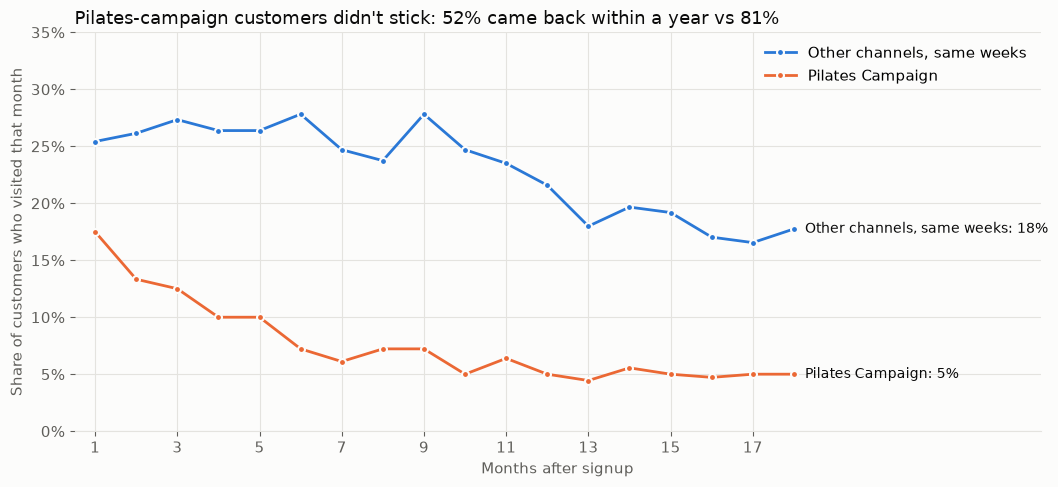

In [18]:
pv["month_after"] = pv["days"] // 30
curve = (pv[pv["month_after"].between(1, 18)].groupby(["group", "month_after"])["customer_id"].nunique()
         .unstack(0).div(cohort.groupby("group").size()) * 100)

fig, ax = plt.subplots(figsize=(11, 5))
for name, colr in [("Other channels, same weeks", BLUE), ("Pilates Campaign", ORANGE)]:
    ax.plot(curve.index, curve[name], color=colr, label=name, marker="o", ms=5, mec="#fcfcfb", mew=1.5)
    ax.annotate(f"{name}: {curve[name].iloc[-1]:.0f}%", (curve.index[-1], curve[name].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=INK, fontsize=10)
ax.set_xlim(0.5, 24)
ax.set_xticks(range(1, 19, 2))
ax.set_ylim(0, 35)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Months after signup")
ax.set_ylabel("Share of customers who visited that month")
ax.legend(loc="upper right", frameon=False)
p, o = pilates.loc["Pilates Campaign"], pilates.loc["Other channels, same weeks"]
ax.set_title(f"Pilates-campaign customers didn't stick: {p['came_back_365d']:.0f}% came back within a year "
             f"vs {o['came_back_365d']:.0f}%", loc="left", color=INK, fontsize=13)
fig.tight_layout()
plt.show()

## 8. Recommendation, KPIs & risks (Stream D, slide 10)
*DRAFT: repairs row confirmed by C-1/C-2 (section 6); loyalty row to confirm with B-1.*

**Answer:** not as planned. Revenue recovered from fewer, older customers spending more (section 3, A), so the
gap is keeping customers, not rewarding the ones who stay. **Keep free repairs:** repair users churn 15% vs 66%
for similar non-users, and scrapping saves $134K a year but risks $366K–$1.47M of profit (section 6). **Fix
loyalty's profit before expanding it.**

In [19]:
since_launch = visits[visits["date"] >= C.LOYALTY_LAUNCH]
pd.Series({
    "Store profit margin since loyalty launch (%)": since_launch["profit"].sum() / since_launch["revenue"].sum() * 100,
    "Redeemed points since launch ($)": since_launch["redeemed_dollars"].sum(),
    "Redeemed points as share of revenue (%)": since_launch["redeemed_dollars"].sum() / since_launch["revenue"].sum() * 100,
}).round(1)

Store profit margin since loyalty launch (%)        57.0
Redeemed points since launch ($)                796635.0
Redeemed points as share of revenue (%)              5.0
dtype: float64

| Area | Recommendation | KPI to track (target) | Risk to watch |
|---|---|---|---|
| Repairs | Keep free repairs, with a 20-day turnaround target | Churn of repair users vs similar non-users (now 15% vs 66%); turnaround ≤ 20 days (over 20 days: 24% churn vs 11–13%) | Some of the gap is self-selection; the case holds unless repairs cause under 9% of it |
| Loyalty | Redesign before expanding: reward visits and retention, not just spend | Profit per member after redemptions; redemptions ≤ [__]% of revenue (now 5.0%) | Extra member revenue reaches profit at about half the normal rate |
| Acquisition | Judge campaigns on retention, not sign-ups | 6- and 12-month return rate of new customers (Pilates: 52% vs 81%) | Campaign customers churn after the offer ends |
| Customer base | Win back 18–24s on the staples the competitor undercut, led by leggings | New 18–24 customers per month; active repeat customers vs pre-competitor (now 94) | A price war erodes margin; growth depends on fewer, older customers |

**Limitations:** members and repair users choose to take part, so matched comparisons reduce but don't remove
selection bias; ARR lags real changes by up to 12 months; the data has no campaign or program running costs
beyond repairs and redeemed points.